## Analyse des fichiers mis à disposition


### --> nomenclature-inca3-janv2021.pdf : 
code_aliment regroupé par Groupe et avec la fréquence

### --> notice-utilisateurs-donnees-inca3-data.gouvjanv21.pdf
1. gens défini par localisation (Zones action Enquêteurs); logements aprmis ceux rescencer (partie avec Enfant et partie avec ou sans) ; par individu
2. le recueil des donnés : pleins de questionnaires en gros et c'est les gens qui disent ce qu'ils font et mangent
3. Recommandations
- pas étudier en même temps adulte et enfant
4. Présentation des tables (à partir page 17)
- Table FQP : fréquence alimentaire par mois de pleins de trucs



Fichiers à regarder

conso-gpe-inca  
apport_nut_aliment  
description_indiv  
habitudes_indiv  

In [58]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


In [59]:
BASE_DIR = Path.cwd()
DOSSIER = BASE_DIR / "tables"

In [60]:
apports_nut_alim = pd.read_csv(f"{DOSSIER}/apports-nut-alim.csv", sep = ';')
conso_gpe_inca3 = pd.read_csv(f"{DOSSIER}/conso-gpe-inca3.csv", sep = ';')
description_indiv = pd.read_csv(f"{DOSSIER}/description-indiv.csv", sep = ';')
habitudes_indiv = pd.read_csv(f"{DOSSIER}/habitudes-indiv.csv", sep = ';')

C:\Users\Sahbine\AppData\Local\Temp\ipykernel_20152\3307531203.py:3: DtypeWarning: Columns (88: veget_autre_alim_libelle) have mixed types. Specify dtype option on import or set low_memory=False.
  description_indiv = pd.read_csv(f"{DOSSIER}/description-indiv.csv", sep = ';')
C:\Users\Sahbine\AppData\Local\Temp\ipykernel_20152\3307531203.py:4: DtypeWarning: Columns (8: repasenfantmidi_autre_libelle, 14: lait_plusvt_boisson_veg_libelle, 16: lait_plusvt_autre_libelle, 36: lait_occ_boisson_veg_libelle, 45: lieu_repas_midi_autre_libelle, 60: collation_aliment1, 61: collation_aliment2, 62: collation_aliment3, 63: collation_aliment4, 195: bib_autre_libelle) have mixed types. Specify dtype option on import or set low_memory=False.
  habitudes_indiv = pd.read_csv(f"{DOSSIER}/habitudes-indiv.csv", sep = ';')


In [61]:
noind_communs = set(apports_nut_alim['NOIND']) & set(conso_gpe_inca3['NOIND']) & set(habitudes_indiv['NOIND']) & set(description_indiv['NOIND']) 

habitudes_indiv = habitudes_indiv[habitudes_indiv["NOIND"].isin(noind_communs)]
conso_gpe_inca3 = conso_gpe_inca3[conso_gpe_inca3["NOIND"].isin(noind_communs)]
apports_nut_alim = apports_nut_alim[apports_nut_alim["NOIND"].isin(noind_communs)]
description_indiv = description_indiv[description_indiv["NOIND"].isin(noind_communs)]

### Etude de Apports_nut_alim

Cette table fournit les apports nutritionnels individuels journaliers estimés à partir des consommées observées sur 2 ou 3 jours de rappels de 24 heures pour les 4 114 
individus de la Pop3, ainsi que la contribution à l’Apport Energétique Sans Alcool (AESA) pour les macronutriments et les apports pour 100 kcal pour les vitamines et 
minéraux.  

In [62]:
apports_nut_alim

,POPULATION,NOIND,nutriment1,nutriment2,nutriment3,nutriment4,nutriment5,nutriment6,nutriment7,nutriment8,...,contrib45,contrib46,contrib47,contrib48,contrib49,contrib50,contrib51,contrib52,contrib53,contrib54
0,Pop3,110100101,2077.7625,2077.2795,83.054970,287.46045,145.453580,118.051110,0.272250,16.439404,...,0.074628,0.946185,0.345410,0.110520,16.502401,0.215986,8.642483,0.106113,0.258121,1.267153
1,Pop3,110100701,1123.7395,1122.6108,42.008881,141.19160,87.729454,40.941555,1.554727,21.721514,...,0.145274,1.462126,0.317232,0.098729,30.148006,0.119924,24.783506,0.252590,0.718946,0.070505
2,Pop3,110100801,2544.5754,2543.0146,87.255280,292.85364,148.375690,123.386040,0.837265,20.448515,...,0.050513,0.944199,0.214649,0.066984,11.707060,0.131240,6.312596,0.114005,0.332603,1.175436
3,Pop3,110101201,2154.6367,1738.7144,64.621910,176.34831,108.290740,52.579441,0.252013,14.028072,...,0.230425,1.569673,0.578777,0.112707,14.442437,0.533786,10.153035,0.224728,1.051633,0.520615
4,Pop3,110101401,1229.2993,1230.0304,44.161503,134.01630,52.806332,67.524727,0.441230,12.723254,...,0.124503,0.932228,0.360054,0.078900,15.277953,0.157646,2.613579,0.183976,0.467196,1.011166
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4109,Pop3,827404801,1744.8936,1737.3795,58.608280,242.33351,95.925667,113.737550,1.575275,27.409937,...,0.084630,0.509743,0.258737,0.052987,15.026357,0.142795,7.349970,0.143217,0.375847,0.271314
4110,Pop3,827510001,1825.1444,1825.3975,61.467087,237.78731,107.761570,111.804200,0.152320,11.937434,...,0.085793,1.186168,0.334268,0.096391,12.278720,0.268007,4.021643,0.247692,0.610921,0.184487
4111,Pop3,828402601,2915.1531,2914.0977,94.783630,312.02029,141.936940,145.166180,0.083440,22.134981,...,0.059071,0.562702,0.170185,0.046554,9.128673,0.181072,1.274047,0.147985,0.471130,0.642486
4112,Pop3,828402701,1693.2689,1692.6514,39.922516,224.54694,117.104230,90.795708,2.391156,23.669191,...,0.046533,0.359910,0.226769,0.052412,17.587523,0.076794,6.618568,0.084453,0.914683,0.055218


In [63]:
def nettoyer_valeur(val):
    if val == "" or (isinstance(val, (list, tuple)) and len(val) == 0):
        return None
    return val

apports_nut_alim = apports_nut_alim.map(nettoyer_valeur)

nb_none = apports_nut_alim.isna().sum().sum()
print(nb_none)

nb_none_par_colonne  = apports_nut_alim.isna().sum()

print(nb_none_par_colonne)

416
POPULATION    0
NOIND         0
nutriment1    0
nutriment2    0
nutriment3    0
             ..
contrib50     8
contrib51     8
contrib52     8
contrib53     8
contrib54     8
Length: 108, dtype: int64


In [64]:
# Filtrer uniquement les colonnes qui contiennent au moins une valeur manquante
colonnes_avec_na = nb_none_par_colonne[nb_none_par_colonne > 0]
nb_colonnes_avec_na = len(colonnes_avec_na)

# 1. Nombre de colonnes avec des données manquantes + nombre pour chacune
print(f"Nombre de colonnes avec des données manquantes : {nb_colonnes_avec_na}")
print("Détail par colonne :")
print(colonnes_avec_na)
print("-" * 40)

# 2. Nom des colonnes où les données manquent
print("Nom des colonnes avec des données manquantes :")
print(list(colonnes_avec_na.index))
print("-" * 40)

# 3. Lignes où des données manquent
lignes_avec_na = apports_nut_alim[apports_nut_alim.isna().any(axis=1)]
print(f"Lignes contenant au moins une valeur manquante (Total : {len(lignes_avec_na)} lignes) :")
print(lignes_avec_na)

Nombre de colonnes avec des données manquantes : 52
Détail par colonne :
contrib3     8
contrib4     8
contrib5     8
contrib6     8
contrib7     8
contrib8     8
contrib9     8
contrib10    8
contrib11    8
contrib12    8
contrib13    8
contrib14    8
contrib15    8
contrib16    8
contrib17    8
contrib18    8
contrib19    8
contrib20    8
contrib21    8
contrib22    8
contrib23    8
contrib24    8
contrib25    8
contrib26    8
contrib27    8
contrib28    8
contrib29    8
contrib30    8
contrib31    8
contrib32    8
contrib33    8
contrib34    8
contrib35    8
contrib36    8
contrib37    8
contrib38    8
contrib39    8
contrib40    8
contrib41    8
contrib42    8
contrib43    8
contrib44    8
contrib45    8
contrib46    8
contrib47    8
contrib48    8
contrib49    8
contrib50    8
contrib51    8
contrib52    8
contrib53    8
contrib54    8
dtype: int64
----------------------------------------
Nom des colonnes avec des données manquantes :
['contrib3', 'contrib4', 'contrib5', 'contrib6

Nous allons supprimer donc toutes les lignes avec des 0 car ce sont des gens qui n'ont pas rempli (Attention retenir les id_indiv)

In [65]:
# 1. Isoler les lignes où la colonne ciblée vaut 0
lignes_a_retirer = apports_nut_alim[apports_nut_alim['nutriment1'] == 0]

# 2. Extraire la liste des NOIND de ces lignes retirées
liste_noind_retires = lignes_a_retirer['NOIND'].tolist()

# 3. Mettre à jour le DataFrame en ne gardant que les lignes différentes de 0
apports_nut_alim = apports_nut_alim[apports_nut_alim['nutriment1'] != 0]

# Affichage pour vérification
print(f"Nombre de lignes retirées : {len(liste_noind_retires)}")
print(f"Liste des NOIND retirés : {liste_noind_retires}")

Nombre de lignes retirées : 8
Liste des NOIND retirés : [122902001, 123501301, 126900201, 222702601, 222901401, 521700101, 522902101, 725702801]


### Etude de Conso-gpe-inca3

Cette table fournit les consommations alimentaires individuelles journalières estimées pour chaque groupe de la nomenclature INCA3 à partir des consommations
observées sur 2 ou 3 jours de rappels de 24 heures pour les 4 114 individus de la Pop3.

In [66]:
conso_gpe_inca3

,POPULATION,NOIND,conso_gpe1,conso_gpe2,conso_gpe3,conso_gpe4,conso_gpe5,conso_gpe6,conso_gpe7,conso_gpe8,...,conso_gpe35,conso_gpe36,conso_gpe37,conso_gpe38,conso_gpe39,conso_gpe40,conso_gpe41,conso_gpe42,conso_gpe43,conso_gpe44
0,Pop3,110100101,60.899998,0.000000,6.666666,161.000000,0.0,41.333332,83.199997,208.333330,...,0.00000,53.666668,0.00000,0.000000,52.500000,35.333332,88.052261,0.000000,0.0,0.0
1,Pop3,110100701,24.000000,0.000000,0.000000,40.000000,0.0,49.714291,0.000000,205.357150,...,211.61903,0.000000,0.00000,80.000008,0.000000,0.000000,3.821429,0.000000,0.0,0.0
2,Pop3,110100801,70.349998,0.000000,0.000000,78.571426,0.0,118.571420,130.742860,0.000000,...,0.00000,0.000000,0.00000,77.428581,89.285713,115.714290,0.000000,0.000000,0.0,0.0
3,Pop3,110101201,9.900001,0.000000,0.000000,58.714287,0.0,130.714280,8.000000,0.000000,...,0.00000,0.000000,0.00000,0.000000,8.571429,0.000000,15.265716,0.000000,0.0,0.0
4,Pop3,110101401,46.618332,0.000000,28.200001,22.666666,0.0,64.666664,0.000000,250.000000,...,0.00000,0.000000,0.00000,0.000000,96.333336,40.666668,27.366667,0.000000,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4109,Pop3,827404801,61.307144,19.971966,0.000000,226.857150,0.0,30.982143,0.000000,44.642857,...,0.00000,0.000000,0.00000,0.000000,0.000000,100.531240,29.016428,0.000000,0.0,0.0
4110,Pop3,827510001,35.357143,0.000000,57.142857,33.928570,0.0,45.714287,0.000000,80.357140,...,0.00000,40.714283,114.28573,0.000000,157.142870,108.571430,34.285713,0.000000,0.0,0.0
4111,Pop3,828402601,59.946426,0.000000,0.000000,0.000000,0.0,199.642850,89.665169,44.642857,...,0.00000,0.000000,0.00000,164.285710,0.000000,268.533290,49.735714,0.000000,0.0,0.0
4112,Pop3,828402701,35.084820,0.000000,0.000000,25.000000,0.0,210.785720,0.000000,0.000000,...,0.00000,0.000000,0.00000,0.000000,223.928560,0.000000,18.542858,35.428574,0.0,0.0


In [67]:
def nettoyer_valeur(val):
    if val == "" or (isinstance(val, (list, tuple)) and len(val) == 0):
        return None
    return val

conso_gpe_inca3 = conso_gpe_inca3.map(nettoyer_valeur)

nb_none = conso_gpe_inca3.isna().sum().sum()
print(nb_none)

nb_none_par_colonne  = conso_gpe_inca3.isna().sum()

print(nb_none_par_colonne)

0
POPULATION     0
NOIND          0
conso_gpe1     0
conso_gpe2     0
conso_gpe3     0
conso_gpe4     0
conso_gpe5     0
conso_gpe6     0
conso_gpe7     0
conso_gpe8     0
conso_gpe9     0
conso_gpe10    0
conso_gpe11    0
conso_gpe12    0
conso_gpe13    0
conso_gpe14    0
conso_gpe15    0
conso_gpe16    0
conso_gpe17    0
conso_gpe18    0
conso_gpe19    0
conso_gpe20    0
conso_gpe21    0
conso_gpe22    0
conso_gpe23    0
conso_gpe24    0
conso_gpe25    0
conso_gpe26    0
conso_gpe27    0
conso_gpe28    0
conso_gpe29    0
conso_gpe30    0
conso_gpe31    0
conso_gpe32    0
conso_gpe33    0
conso_gpe34    0
conso_gpe35    0
conso_gpe36    0
conso_gpe37    0
conso_gpe38    0
conso_gpe39    0
conso_gpe40    0
conso_gpe41    0
conso_gpe42    0
conso_gpe43    0
conso_gpe44    0
dtype: int64


### Nettoyage des données générales

- 0 quantité négative

## Retrouver les apports par personne


Dans le projet il est plus ou moins demander de retrouver les valeurs pour cela nous avons besoin de : 
- **conso-compo-alim-vf-mad-datagou** : pour chaque individu tous les aliments mangés, leur teneur en pleins de trucs, la quantité, le gpe_INCA3

## BONUS : Etude de habitudes_indiv

Cette table contient les données des questionnaires auto-administrés relatifs aux volets « Habitudes alimentaires » et « Origine des aliments ».  
Elle regroupe les informations suivantes : lieux et occasions de consommation, consommations hors-foyer et entre les repas, préférences alimentaires, présence de
sel/beurre/sauce sur la table au moment des repas, lecture des étiquettes, sources d’informations en alimentation, consommation de denrées animales crues et des
croûtes de fromage, préparation des fruits et légumes crus, spécificités de l’alimentation des enfants de 0 à 35 mois (ex : allaitement (exclusif ou partiel), type de laits
consommés, diversification alimentaire, matériaux des biberons et des tétines, préparation, stockage et conservation des biberons de lait, mode de chauffage des
laits et contenants utilisés), autoconsommation et utilisation de produits phytosanitaires au potager, consommation d’aliments issus de l’agriculture biologique et
cuisson des aliments au barbecue.

In [68]:
habitudes_indiv

,POPULATION,NOIND,periode_reference,repasenfantmidi_vous,repasenfantmidi_am,repasenfantmidi_creche,repasenfantmidi_parent,repasenfantmidi_autre,repasenfantmidi_autre_libelle,repasenfant_freq,...,conso_legumes_secs_bio_tjr_svt,conso_cereales_bio_tjr_svt,conso_pain_bio_tjr_svt,conso_autres_alim_bio_tjr_svt,conso_barbecue,conso_barbecue_elec,conso_barbecue_bois,conso_barbecue_gaz,conso_barbecue_printps_ete_freq,conso_barbecue_automn_hiver_freq
0,Pop2 Individu,110100101,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.0,0.0,NaN,1.0,0.0,1.0,0.0,3.0,1.0
1,Pop2 Individu,110100701,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,NaN,1.0,0.0,1.0,1.0,4.0,1.0
2,Pop2 Individu,110100801,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,3.0,2.0
3,Pop2 Individu,110101201,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,4.0,2.0
4,Pop2 Individu,110101401,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.0,1.0,0.0,2.0,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4367,Pop2 Individu,827404801,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,3.0,1.0
4368,Pop2 Individu,827510001,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,2.0,NaN,NaN,NaN,NaN,NaN
4369,Pop2 Individu,828402601,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,1.0,1.0,NaN,1.0,0.0,1.0,0.0,5.0,3.0
4370,Pop2 Individu,828402701,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,1.0,1.0,1.0,2.0,NaN,NaN,NaN,NaN,NaN


In [69]:
def nettoyer_valeur(val):
    if val == "" or (isinstance(val, (list, tuple)) and len(val) == 0):
        return None
    return val

habitudes_indiv = habitudes_indiv.map(nettoyer_valeur)

nb_none = habitudes_indiv.isna().sum().sum()
print(nb_none)

nb_none_par_colonne  = habitudes_indiv.isna().sum()

print(nb_none_par_colonne)

923929
POPULATION                             0
NOIND                                  0
periode_reference                      0
repasenfantmidi_vous                3830
repasenfantmidi_am                  3830
                                    ... 
conso_barbecue_elec                  601
conso_barbecue_bois                  601
conso_barbecue_gaz                   601
conso_barbecue_printps_ete_freq      619
conso_barbecue_automn_hiver_freq     651
Length: 389, dtype: int64


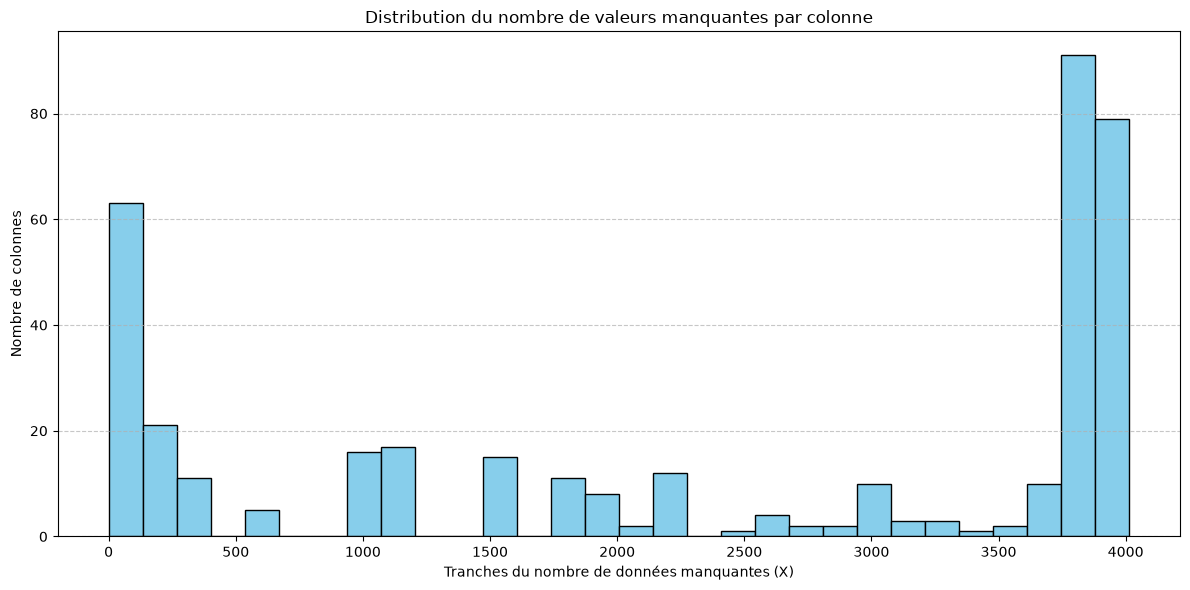

In [70]:
plt.figure(figsize=(12, 6))

# On groupe les données en 30 classes/intervalles pour éviter l'engorgement de l'axe X
plt.hist(nb_none_par_colonne, bins=30, color='skyblue', edgecolor='black')

plt.title("Distribution du nombre de valeurs manquantes par colonne")
plt.xlabel("Tranches du nombre de données manquantes (X)")
plt.ylabel("Nombre de colonnes")
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [71]:
nb_none_par_colonne_triee = nb_none_par_colonne.sort_values(ascending=True)
print(nb_none_par_colonne_triee)

POPULATION                             0
NOIND                                  0
periode_reference                      0
conso_aliments_bio                    26
consommation_bio_type                 36
                                    ... 
lait_occ_li_autre_anim_libelle      4013
lait_plusvt_pi_autre_veg_libelle    4013
lait_occ_autre_libelle              4013
prepbb_chauff_autre_libelle         4013
lait_plusvt_autre_anim_libelle      4013
Length: 389, dtype: int64


In [72]:
habitudes_indiv_temp = habitudes_indiv.copy()
print(habitudes_indiv_temp.shape)

(4013, 389)


In [73]:
colonnes_supprimees = nb_none_par_colonne[nb_none_par_colonne >= 4013].index.tolist()
print(colonnes_supprimees)

habitudes_indiv_temp = habitudes_indiv_temp.loc[:, nb_none_par_colonne < 4013]
print(habitudes_indiv_temp.shape)

['lait_plusvt_li_autr_anim_libelle', 'lait_plusvt_pi_autre_veg_libelle', 'lait_plusvt_autre_anim_libelle', 'lait_occ_li_autre_anim_libelle', 'lait_occ_pi_autre_veg_libelle', 'lait_occ_autre_libelle', 'prepbb_chauff_autre_libelle', 'conso_nsp']
(4013, 381)


In [74]:
nb_none_par_colonne = nb_none_par_colonne[nb_none_par_colonne < 4013]
nb_none_par_colonne_triee = nb_none_par_colonne_triee[nb_none_par_colonne_triee < 4013]

print(nb_none_par_colonne_triee)

POPULATION                            0
NOIND                                 0
periode_reference                     0
conso_aliments_bio                   26
consommation_bio_type                36
                                   ... 
repasenfantmidi_autre_libelle      4010
bib_autre_libelle                  4011
lait_plusvt_autre_libelle          4011
lait_plusvt_boisson_veg_libelle    4011
lait_occ_boisson_veg_libelle       4012
Length: 381, dtype: int64


In [75]:
# regarder le type de chaque colonne
# Afficher les noms des colonnes de type str
colonnes_str = habitudes_indiv_temp.select_dtypes(include=['object', 'str']).columns.tolist()

print("Colonnes de type str :")
print(colonnes_str)

# Afficher le nombre de colonnes par type
print("\nNombre de colonnes par type :")
print(habitudes_indiv_temp.dtypes.value_counts())

Colonnes de type str :
['POPULATION', 'repasenfantmidi_autre_libelle', 'lait_plusvt_boisson_veg_libelle', 'lait_plusvt_autre_libelle', 'lait_occ_boisson_veg_libelle', 'lait_occ_autre_anim_libelle', 'lieu_repas_midi_autre_libelle', 'cantine_jms_autre_raison_libelle', 'collation_aliment1', 'collation_aliment2', 'collation_aliment3', 'collation_aliment4', 'collation_matin_aliment1', 'collation_matin_aliment2', 'collation_matin_aliment3', 'collation_matin_aliment4', 'distributeur_autre_libelle', 'source_autre_libelle', 'sterilisation_bib_libelle', 'sterilisation_tetine_libelle', 'bib_autre_libelle', 'conserv_eau_libelle', 'lieu_conserv_bib_li_libelle', 'conso_autres_libelle', 'autoproduction_volailles_libelle', 'autoproduction_viandes_libelle', 'autoproduction_tomates_libelle', 'autoproduction_carottes_libelle', 'autoproduction_salades_libelle', 'autoproduction_abricots_libelle', 'autoproduction_pommes_libelle', 'autoproduction_fraises_libelle', 'autoproduction_autrfruit_libelle', 'autopro

In [76]:
nb_str = len(habitudes_indiv_temp.select_dtypes(include=['object', 'string']).columns)
nb_num = len(habitudes_indiv_temp.select_dtypes(include=['number']).columns)

print("--- Décompte des types de colonnes ---")
print(f"Nombre de colonnes au format texte (str) : {nb_str}")
print(f"Nombre de colonnes au format numérique (int/float) : {nb_num}")
print('\n')

d_str = habitudes_indiv_temp.select_dtypes(include=['object', 'string'])
for k in d_str.columns:
    print(f"Colonne '{k}' : {d_str[k].nunique()} valeurs uniques, {d_str[k].isna().sum()} valeurs manquantes")
    print(d_str[k].unique())

--- Décompte des types de colonnes ---
Nombre de colonnes au format texte (str) : 39
Nombre de colonnes au format numérique (int/float) : 342


Colonne 'POPULATION' : 1 valeurs uniques, 0 valeurs manquantes
<StringArray>
['Pop2 Individu']
Length: 1, dtype: str
Colonne 'repasenfantmidi_autre_libelle' : 3 valeurs uniques, 4010 valeurs manquantes
<StringArray>
[                                                                   nan,
 '2 JOURS ET DEMI CHEZ LA NOURRICE, LE RESTE DE LA SEMAINE A LA MAISON',
                         'PAR UNE ASSISTANTE MATERNELLE ET PAR SA MERE',
                                                       'HALTE GARDERIE']
Length: 4, dtype: str
Colonne 'lait_plusvt_boisson_veg_libelle' : 2 valeurs uniques, 4011 valeurs manquantes
<StringArray>
[                                             nan,
                       'EPEAUTRE, AVOINE, MILLET',
 'RIZ, AVOINE, EPEAUTRE, RIZ CHATAIGNE ET AVOINE']
Length: 3, dtype: str
Colonne 'lait_plusvt_autre_libelle' : 1 valeurs un

On s'en fout des libelles : Il est plus interessant de ne garder que les fréquences on s'en fiche des différents autres choses

les collation comment gérer ? Je dirais de les garder et de faire des grandes catégories pour différencier les différentes collation


In [77]:
colonnes_libelle = habitudes_indiv_temp.columns[habitudes_indiv_temp.columns.str.endswith("_libelle")]
habitudes_indiv_temp.drop(columns=colonnes_libelle, inplace=True)
print(habitudes_indiv_temp.shape)

nb_none_par_colonne = nb_none_par_colonne.drop(index=colonnes_libelle, errors="ignore")
nb_none_par_colonne_triee = nb_none_par_colonne.sort_values(ascending=False)
print(nb_none_par_colonne_triee)

nb_str = len(habitudes_indiv_temp.select_dtypes(include=['object', 'string']).columns)
nb_num = len(habitudes_indiv_temp.select_dtypes(include=['number']).columns)

print("--- Décompte des types de colonnes ---")
print(f"Nombre de colonnes au format texte (str) : {nb_str}")
print(f"Nombre de colonnes au format numérique (int/float) : {nb_num}")
print('\n')

(4013, 351)
conso_autres_age        4009
stockage_bib_lm         4006
delai_conso_bib_lm      4006
conso_autres_age_nsp    4003
tps_conserv_bib_li      4002
                        ... 
consommation_bio          36
conso_aliments_bio        26
NOIND                      0
POPULATION                 0
periode_reference          0
Length: 351, dtype: int64
--- Décompte des types de colonnes ---
Nombre de colonnes au format texte (str) : 9
Nombre de colonnes au format numérique (int/float) : 342




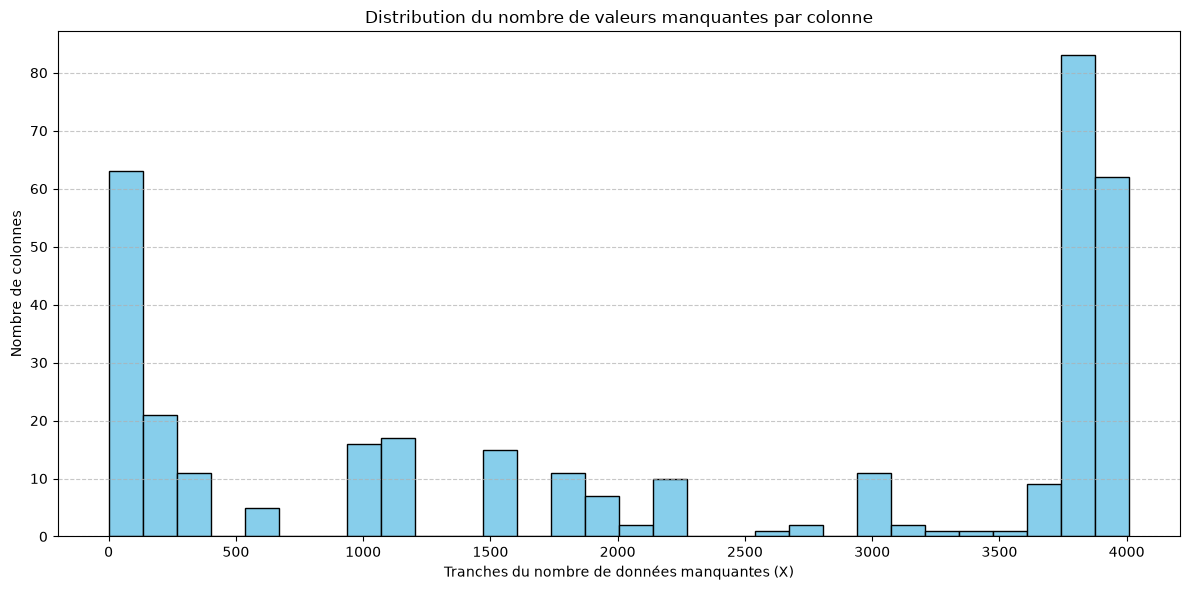

In [78]:
plt.figure(figsize=(12, 6))

# On groupe les données en 30 classes/intervalles pour éviter l'engorgement de l'axe X
plt.hist(nb_none_par_colonne, bins=30, color='skyblue', edgecolor='black')

plt.title("Distribution du nombre de valeurs manquantes par colonne")
plt.xlabel("Tranches du nombre de données manquantes (X)")
plt.ylabel("Nombre de colonnes")
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

### Séparation des données entre adultes et enfants

Il est nécessaire dans les habitudes de séparer le dataframe entre adulte et enfants car certaines habitudes ne fonctionnent que pour les enfants et inversement.  

donc : on lie à description pour ne récupérer que l'age

ATTENTION : bien sélectionner PS : personne sélectionné et pas PR

format_tage_PS :  
1 0-11 mois  
2 1-3 ans  
3 4-6 ans  
4 7-10 ans  
5 11-14 ans  
6 15-17 ans  
7 18-44 ans  
8 45-64 ans  
9 65-79 ans  

format_tage_PS_mois  
1 0-15 mois  
2 16-24 mois  
3 25-35 mois  

Nous allons donc diviser en 3 classes :  
- les bébés : tage_PS [1, 2] // tout tage_PS_mois
- les enfants : tage_PS [3, 4, 5, 6] // aucun tage_PS_mois
- les adultes : tage_PS [7, 8, 9] // aucun tage_PS_mois

In [79]:
print(description_indiv['tage_PS_mois'])

0      NaN
1      NaN
2      NaN
3      NaN
4      NaN
        ..
5849   NaN
5850   NaN
5852   NaN
5853   NaN
5854   NaN
Name: tage_PS_mois, Length: 4013, dtype: float64


In [80]:
habitudes_indiv_temp = habitudes_indiv_temp.merge(description_indiv[['NOIND', 'tage_PS','tage_PS_mois']], on = 'NOIND')
print(habitudes_indiv_temp.shape)

(4013, 353)


In [81]:
# générer les 3 habitudes_indiv
habitude_bb = habitudes_indiv_temp[habitudes_indiv_temp['tage_PS'] <= 2]
habitude_enf = habitudes_indiv_temp[(habitudes_indiv_temp['tage_PS'] >= 3) & (habitudes_indiv_temp['tage_PS']  < 6)]
habitude_ad = habitudes_indiv_temp[habitudes_indiv_temp['tage_PS'] >= 7]

print(habitude_bb.shape)
print(habitude_enf.shape)
print(habitude_ad.shape)

(218, 353)
(1349, 353)
(2053, 353)


In [82]:
nb_none_bb  = habitude_bb.isna().sum()
print(nb_none_bb)
print('Somme : ', habitude_bb.isna().sum().sum())

print()
nb_none_enf  = habitude_enf.isna().sum()
print(nb_none_enf)
print('Somme : ', habitude_enf.isna().sum().sum())

print()
nb_none_ad  = habitude_ad.isna().sum()
print(nb_none_ad)
print('Somme : ', habitude_ad.isna().sum().sum())

POPULATION                            0
NOIND                                 0
periode_reference                     0
repasenfantmidi_vous                 35
repasenfantmidi_am                   35
                                   ... 
conso_barbecue_gaz                  139
conso_barbecue_printps_ete_freq     139
conso_barbecue_automn_hiver_freq    145
tage_PS                               0
tage_PS_mois                         33
Length: 353, dtype: int64
Somme :  41710

POPULATION                             0
NOIND                                  0
periode_reference                      0
repasenfantmidi_vous                1349
repasenfantmidi_am                  1349
                                    ... 
conso_barbecue_gaz                    94
conso_barbecue_printps_ete_freq      101
conso_barbecue_automn_hiver_freq     107
tage_PS                                0
tage_PS_mois                        1349
Length: 353, dtype: int64
Somme :  279036

POPULATION              

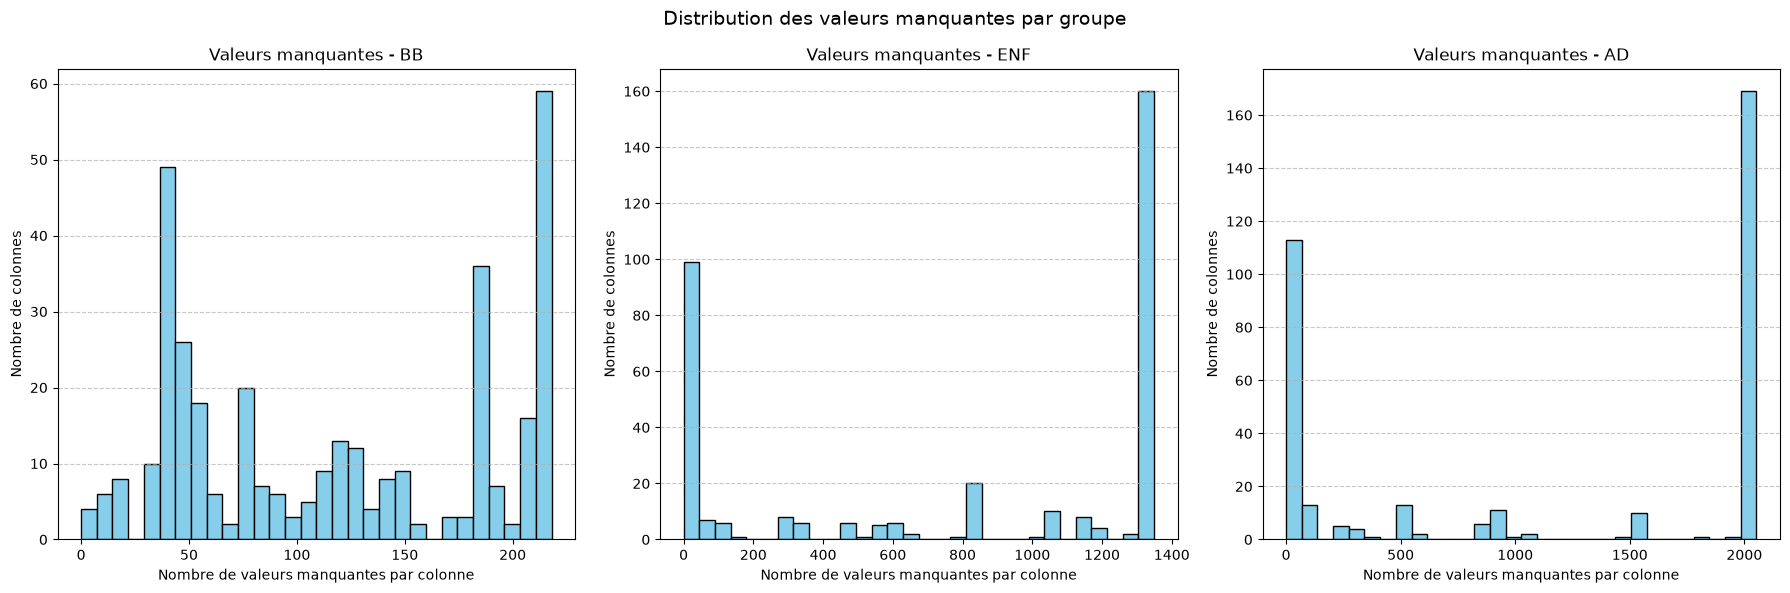

In [83]:
# Création d'une figure avec 3 graphiques côte à côte
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Données et titres des graphiques
donnees = [
    (nb_none_bb, "BB"),
    (nb_none_enf, "ENF"),
    (nb_none_ad, "AD")
]

for ax, (nb_none, titre) in zip(axes, donnees):
    ax.hist(nb_none, bins=30, color="skyblue", edgecolor="black")
    ax.set_title(f"Valeurs manquantes - {titre}")
    ax.set_xlabel("Nombre de valeurs manquantes par colonne")
    ax.set_ylabel("Nombre de colonnes")
    ax.grid(axis="y", linestyle="--", alpha=0.7)

fig.suptitle("Distribution des valeurs manquantes par groupe", fontsize=14)
plt.tight_layout()
plt.show()


In [84]:
# BB
nb_colonnes_avant = habitude_bb.shape[1]
habitude_bb = habitude_bb.dropna(axis=1, how='all')
nb_supprimees_bb = nb_colonnes_avant - habitude_bb.shape[1]

# ENF
nb_colonnes_avant = habitude_enf.shape[1]
habitude_enf = habitude_enf.dropna(axis=1, how='all')
nb_supprimees_enf = nb_colonnes_avant - habitude_enf.shape[1]

# AD
nb_colonnes_avant = habitude_ad.shape[1]
habitude_ad = habitude_ad.dropna(axis=1, how='all')
nb_supprimees_ad = nb_colonnes_avant - habitude_ad.shape[1]

# Résultats
print("Colonnes supprimées :")
print(f"BB  : {nb_supprimees_bb}")
print(f"ENF : {nb_supprimees_enf}")
print(f"AD  : {nb_supprimees_ad}")
print(f"Total : {nb_supprimees_bb + nb_supprimees_enf + nb_supprimees_ad}")

Colonnes supprimées :
BB  : 42
ENF : 158
AD  : 168
Total : 368


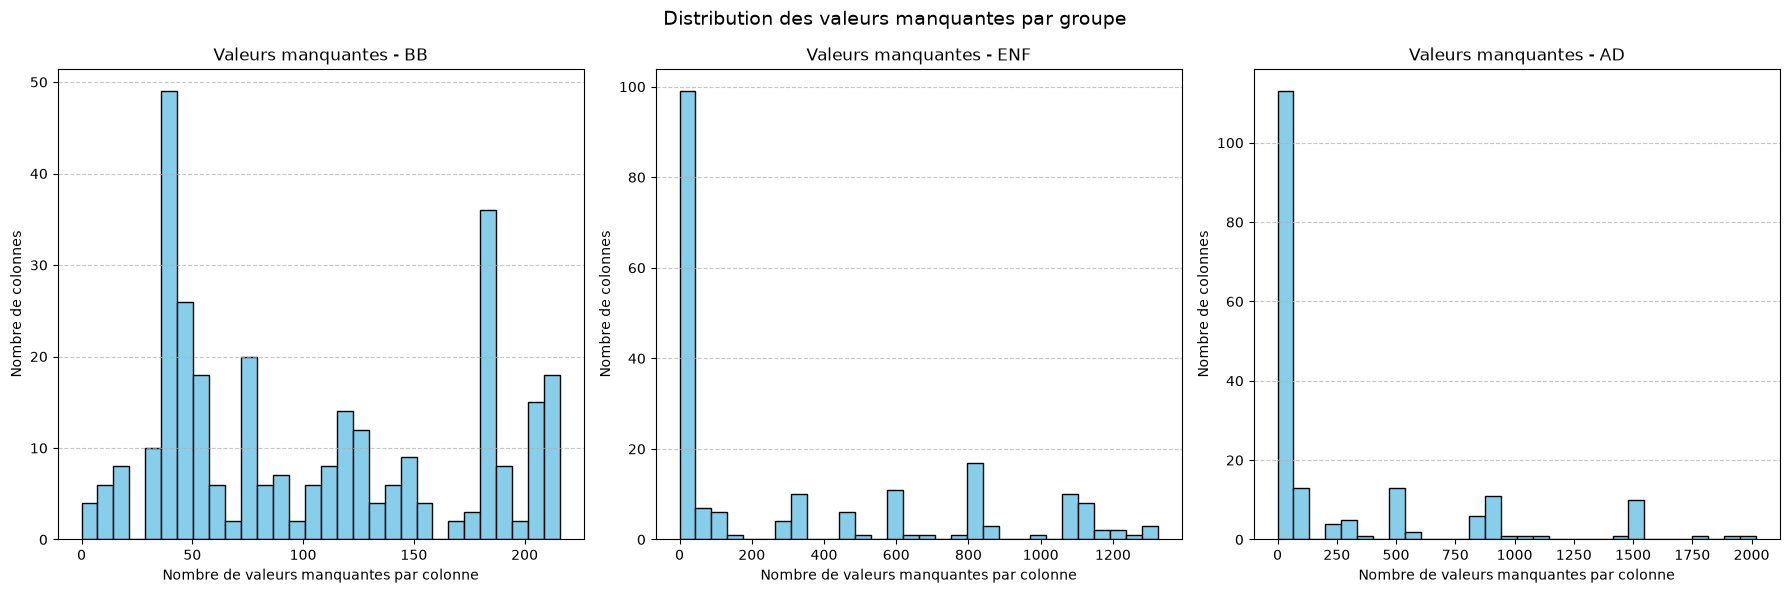

In [ ]:
nb_none_bb  = habitude_bb.isna().sum()
nb_none_enf  = habitude_enf.isna().sum()
nb_none_ad  = habitude_ad.isna().sum()

# Création d'une figure avec 3 graphiques côte à côte
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Données et titres des graphiques
donnees = [
    (nb_none_bb, "BB"),
    (nb_none_enf, "ENF"),
    (nb_none_ad, "AD")
]

for ax, (nb_none, titre) in zip(axes, donnees):
    ax.hist(nb_none, bins=30, color="skyblue", edgecolor="black")
    ax.set_title(f"Valeurs manquantes - {titre}")
    ax.set_xlabel("Nombre de valeurs manquantes par colonne")
    ax.set_ylabel("Nombre de colonnes")
    ax.grid(axis="y", linestyle="--", alpha=0.7)

fig.suptitle("Distribution des valeurs manquantes par groupe", fontsize=14)
plt.tight_layout()
plt.show()

In [87]:
print("Colonne de BB")
print(habitude_bb.columns)

print()
print("Colonne de enfant")
print(habitude_enf.columns)

print()
print("Colonne de adult")
print(habitude_ad.columns)

Colonne de BB
Index(['POPULATION', 'NOIND', 'periode_reference', 'repasenfantmidi_vous',
       'repasenfantmidi_am', 'repasenfantmidi_creche',
       'repasenfantmidi_parent', 'repasenfantmidi_autre', 'repasenfant_freq',
       'conso_bebe_sein',
       ...
       'conso_pain_bio_tjr_svt', 'conso_autres_alim_bio_tjr_svt',
       'conso_barbecue', 'conso_barbecue_elec', 'conso_barbecue_bois',
       'conso_barbecue_gaz', 'conso_barbecue_printps_ete_freq',
       'conso_barbecue_automn_hiver_freq', 'tage_PS', 'tage_PS_mois'],
      dtype='str', length=311)

Colonne de enfant
Index(['POPULATION', 'NOIND', 'periode_reference', 'etablissement_scolaire',
       'cantine_freq', 'cantine_jms_persfoyer', 'cantine_jms_veutpas',
       'cantine_jms_probsante', 'cantine_jms_repaspasequilibre',
       'cantine_jms_repaspasqualite',
       ...
       'conso_cereales_bio_tjr_svt', 'conso_pain_bio_tjr_svt',
       'conso_autres_alim_bio_tjr_svt', 'conso_barbecue',
       'conso_barbecue_elec', 'conso

lieu_repas_midi                      28
cantine_freq                         58
collation_freq                       29
collation_aliment1                  590
collation_aliment2                  982
                                   ... 
conso_barbecue_elec                 325
conso_barbecue_bois                 325
conso_barbecue_gaz                  325
conso_barbecue_printps_ete_freq     335
conso_barbecue_automn_hiver_freq    356
Length: 180, dtype: int64


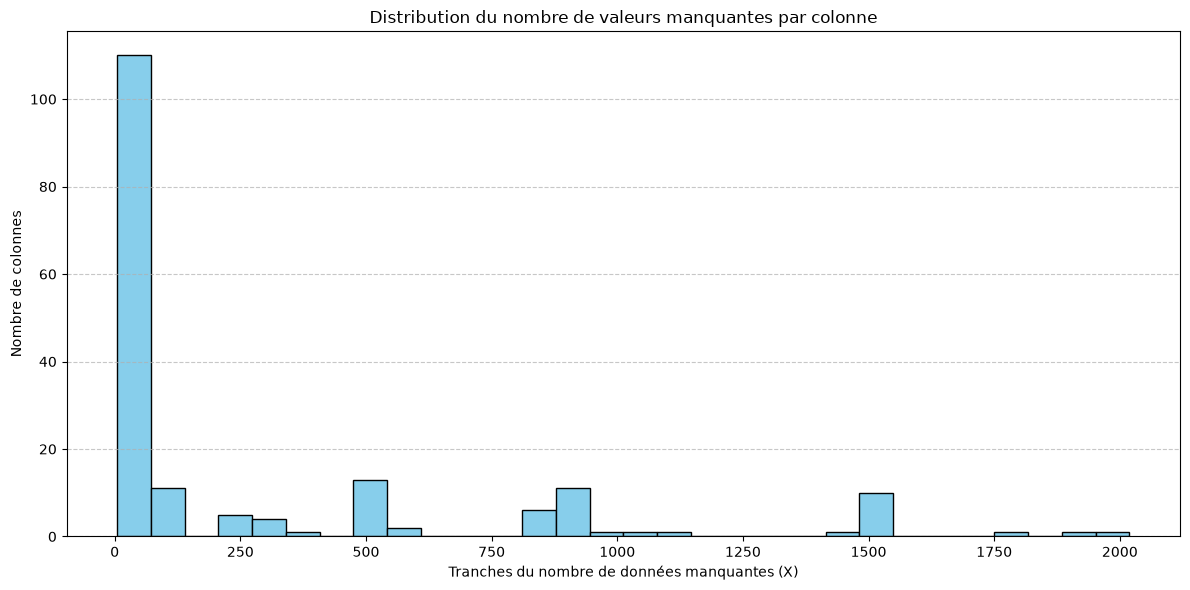

In [89]:
print(nb_none_ad[nb_none_ad != 0])

plt.figure(figsize=(12, 6))

# On groupe les données en 30 classes/intervalles pour éviter l'engorgement de l'axe X
plt.hist(nb_none_ad[nb_none_ad != 0], bins=30, color='skyblue', edgecolor='black')

plt.title("Distribution du nombre de valeurs manquantes par colonne")
plt.xlabel("Tranches du nombre de données manquantes (X)")
plt.ylabel("Nombre de colonnes")
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()